# Part 8: The Kolmogorov Distance — Measuring What the Theorem Bounds

Parts 1 to 6 all measure the same quantity: the distance between the particle filter's posterior
**mean** and the Kalman filter's. Part 6 pushed that quantity to $T = 10^6$ and found the
worst-case value growing like $(\log T)^{1.75}$ — well above the $\sqrt{\log T}$ of Del Moral &
Gerber (2026), Section 7.5.1 — and had to close with a caveat: the two are *different metrics*. The
theorem bounds the **Kolmogorov distance** between the particle approximation and its target, which
is a difference of two probabilities and so can never exceed $1$. The distance between posterior
means has no such ceiling. A quantity that is bounded and a quantity that is not cannot be compared
by their growth rates.

This notebook removes the caveat by measuring the bounded quantity directly.

### What is computed

For a unit direction $u$, both laws are projected onto the real line and compared by their CDFs:

$$D_u(t) \;=\; \sup_{z \in \mathbb{R}} \;\Big| \underbrace{\textstyle\sum_{i} w_t^i \,\mathbf{1}\{u'x_t^i \le z\}}_{\text{weighted particle cloud}} \;-\; \underbrace{\Phi\!\left(\frac{z - u'm_t}{\sqrt{u'P_t u}}\right)}_{\text{exact Kalman posterior}} \Big|$$

and the reported distance is $\max_u D_u(t)$ over a set of directions. Projecting a Gaussian onto a
line leaves a Gaussian with mean $u'm_t$ and variance $u'P_t u$, so no multivariate normal CDF is
ever needed; and because the empirical CDF is a staircase, the supremum over $z$ is attained at the
particles themselves, so it is a maximum over $N$ points rather than a search.

Taken over the $d$ coordinate axes this is the largest **marginal** Kolmogorov distance. Taken over
many directions it approaches the supremum over half-spaces. Every version is a difference of
probabilities, so every version lies in $[0, 1]$ — which is the property that matters here.

### The four questions

1. **Section 4.** On a bounded metric, how does the error grow with $T$? Part 6's answer on the
   unbounded metric was a factor of $7.1$–$9.4$ for the worst case and $1.06$–$1.16$ for the mean.
2. **Section 4.** Is the growth consistent with $\sqrt{\log T}$, which over $T: 10^2 \to 10^6$
   predicts a factor of exactly $\sqrt{3} \approx 1.73$?
3. **Section 5.** If the summaries of the per-step distance turn out to be flat in $T$ while only
   the maximum grows, then nothing is accumulating: the maximum is just the largest of more draws
   from an unchanging distribution. That has a sharp consequence. The maximum over a horizon $T$
   should be predictable from the $(1 - 1/T)$ quantile of the distance, measured once, with nothing
   fitted. Either that prediction works, or something really does degrade over time.
4. **Section 6.** Section 7.5.2 of the paper says that for a fixed target precision $N$ must grow
   like $\log T$, and that this is sharp. That makes a testable prediction: $D \times \sqrt{N}$
   should depend on $T$ alone, so curves for different $N$ must collapse onto one. Part 6 tested
   this on the mean distance and found no collapse, but noted it was the wrong metric to test it on.
   This is the right one.

> **Dependency note.** This notebook adds three functions to `filters.py` — `normal_cdf`,
> `unit_directions` and `weighted_ks_vs_gaussian` — and one optional argument, `stat_fn`, to
> `particle_filter_md`. The argument lets a per-step diagnostic be computed on the fly and the
> particle cloud then discarded, which is what makes $T = 10^6$ possible at all: storing the cloud
> would need about $16$ GB, while the statistic is a scalar per step. With `stat_fn=None` the filter
> is bit-identical to the version used in Parts 1–6.

---
## Section 0 — Setup

`QUICK = True` runs a reduced grid in about two minutes, for checking the code end to end.
`QUICK = False` is the real run.

In [1]:
import math
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from filters import (build_model, simulate_data_md, kalman_filter_md,
                     particle_filter_md, unit_directions,
                     weighted_ks_vs_gaussian, normal_cdf)

QUICK = False          # <-- True for a ~2 minute smoke test

if QUICK:
    T_GRID  = [100, 1_000, 10_000]
    SEEDS   = {100: 4, 1_000: 4, 10_000: 2}
    N_GRID  = [250, 1000]
    T_N     = [1_000, 10_000]
    SEEDS_N = 2
    N_RANDOM_DIRS = 16
else:
    T_GRID  = [100, 1_000, 10_000, 100_000, 1_000_000]
    SEEDS   = {100: 8, 1_000: 8, 10_000: 4, 100_000: 2, 1_000_000: 1}
    N_GRID  = [250, 1000, 4000]
    T_N     = [1_000, 10_000, 100_000]
    SEEDS_N = 3
    N_RANDOM_DIRS = 64

CASES     = [(2, 2, "M = d"), (2, 4, "M > d"), (4, 2, "M < d")]
B_VALS    = [0.9, 1.0]
N_PART    = 1000
COUPLING  = 0.3         # as in Parts 2-6
DATA_SEED = 42
QS        = (0.5, 0.9, 0.99, 0.999)     # quantiles of the per-step distance

CASE_COLOR = {"M = d": "tab:blue", "M > d": "tab:green", "M < d": "tab:red"}
B_STYLE    = {0.9: "-", 1.0: "--"}
B_MARKER   = {0.9: "o", 1.0: "s"}

plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
# Spurious floating-point warnings from matmul on this BLAS build; the values
# themselves are finite and correct. Same filter as Part 6.
warnings.filterwarnings("ignore", message=".*encountered in matmul")

print(f"QUICK   = {QUICK}")
print(f"T grid  : {T_GRID}")
print(f"seeds   : {SEEDS}")
print(f"regimes : {[c[2] for c in CASES]}")
print(f"rho(F)  : {B_VALS}   (coupling = {COUPLING}, N = {N_PART})")

QUICK   = False
T grid  : [100, 1000, 10000, 100000, 1000000]
seeds   : {100: 8, 1000: 8, 10000: 4, 100000: 2, 1000000: 1}
regimes : ['M = d', 'M > d', 'M < d']
rho(F)  : [0.9, 1.0]   (coupling = 0.3, N = 1000)


In [2]:
def ks_run(d, M, b, N, T, data_seed=DATA_SEED, pf_seed=0, n_random=0,
           stat_every=1, keep=False, proposal="bootstrap"):
    """One (d, M, b, N, T) run, summarised by its Kolmogorov distances.

    The particle cloud is never stored. `weighted_ks_vs_gaussian` is handed to
    `particle_filter_md` as `stat_fn`, so each step contributes one scalar and
    the N particles are then discarded. At T = 10^6 and N = 1000 the full
    history would be about 16 GB; the statistic is 8 MB.

    `gap` is recomputed alongside it -- the Parts 1-6 metric, the Euclidean
    distance between the two posterior means -- so that the bounded and
    unbounded measurements come from the very same run and the comparison is
    not confounded by different data or different seeds.
    """
    F, Q, H, R = build_model(d, M, b=b, coupling=COUPLING)
    x, y = simulate_data_md(F, Q, H, R, T=T, seed=data_seed)
    m, P = kalman_filter_md(y, F, Q, H, R)
    dirs = unit_directions(d, n_random, seed=11)

    def stat(t, particles, weights):
        return weighted_ks_vs_gaussian(particles, weights, m[t], P[t], dirs)

    est, ess, resampled, ks = particle_filter_md(
        y, F, Q, H, R, N=N, seed=pf_seed, proposal=proposal,
        stat_fn=stat, stat_every=stat_every)

    gap = np.linalg.norm(est - m, axis=1)
    q = np.quantile(ks, QS)
    out = {"d": d, "M": M, "b": b, "N": N, "T": T,
           "ks_mean": float(ks.mean()), "ks_max": float(ks.max()),
           "ks_q50": q[0], "ks_q90": q[1], "ks_q99": q[2], "ks_q999": q[3],
           "frac_25": float((ks > 0.25).mean()),
           "frac_50": float((ks > 0.50).mean()),
           "gap_mean": float(gap.mean()), "gap_max": float(gap.max()),
           "ess_min": float(ess.min()), "ess_mean": float(ess.mean()),
           "resample_rate": float(resampled.mean())}
    if keep:
        out.update({"ks": ks, "gap": gap, "ess": ess, "kf_cov": P, "kf_mean": m})
    return out


def average_runs(runs):
    """Mean of the scalar fields across repeat seeds."""
    return {k: float(np.mean([r[k] for r in runs])) for k in runs[0]
            if isinstance(runs[0][k], (int, float, np.floating))}


print("ks_run defined -- one smoke call:")
_t0 = time.time()
_r = ks_run(2, 2, 0.9, 500, 500)
print(f"  d=M=2, b=0.9, N=500, T=500 in {time.time()-_t0:.2f}s")
print(f"  mean distance {_r['ks_mean']:.4f}   max {_r['ks_max']:.4f}   "
      f"min ESS {_r['ess_min']:.1f}")

ks_run defined -- one smoke call:
  d=M=2, b=0.9, N=500, T=500 in 0.07s
  mean distance 0.0906   max 0.5566   min ESS 5.0


---
## Section 1 — Three checks on the metric before using it

A new measurement is worth nothing until it has been tested on cases where the answer is known in
advance. Three such cases are available.

1. **The normal CDF itself.** `numpy` has no error function and `scipy` is not a dependency of this
   repo, so `normal_cdf` uses the Zelen & Severo rational approximation. Its error is checked
   against `math.erf`, which is correct to double precision.
2. **An exact sample from the target.** Draw $N$ independent points from the very Gaussian being
   compared against and weight them equally. The distance is then pure Monte Carlo noise, and
   classical theory says it must fall like $N^{-1/2}$ with $D\sqrt{N}$ settling to a constant of
   order one.
3. **A deliberately wrong target.** Compare a large sample against a Gaussian shifted by a known
   amount. The distance must converge to the analytic supremum between two Gaussians, which can be
   computed independently on a fine grid.

A fourth, degenerate case pins down the other end of the scale, and matters later: if a single
particle carries all the weight and sits exactly at the posterior mean, the empirical CDF jumps from
$0$ to $1$ there while the exact CDF passes through $0.5$, so the distance must be exactly $0.5$.

In [3]:
# --- Check 1: normal_cdf against math.erf -------------------------------------
grid = np.unique(np.concatenate([np.linspace(-40, 40, 400_001),
                                 np.linspace(-1.5, 1.5, 100_001)]))
exact = np.array([0.5 * (1.0 + math.erf(v / math.sqrt(2.0))) for v in grid])
err = np.abs(normal_cdf(grid) - exact)

print(f"Check 1 -- normal_cdf vs math.erf over {grid.size:,} points on [-40, 40]")
print(f"  max absolute error : {err.max():.3e}   (at x = {grid[err.argmax()]:+.4f})")
print(f"  mean absolute error: {err.mean():.3e}")
print(f"  The distances measured below are of order 1e-2 to 1e-1, so this sits")
print(f"  {1e-2 / err.max():,.0f}x below the smallest signal of interest.")

Check 1 -- normal_cdf vs math.erf over 499,802 points on [-40, 40]
  max absolute error : 7.452e-08   (at x = +0.7174)
  mean absolute error: 1.275e-08
  The distances measured below are of order 1e-2 to 1e-1, so this sits
  134,198x below the smallest signal of interest.


In [4]:
# --- Check 2: an exact, equally weighted sample from the target ---------------
rng = np.random.default_rng(0)
m_t = np.array([0.3, -1.2])
P_t = np.array([[2.0, 0.7], [0.7, 1.0]])
L_t = np.linalg.cholesky(P_t)
dirs_2 = unit_directions(2, 0)                    # the two coordinate axes
N_CHECK = [250, 1_000, 4_000, 16_000, 64_000]
REPS = 40

rows = []
for N in N_CHECK:
    vals = np.array([
        weighted_ks_vs_gaussian(m_t + rng.standard_normal((N, 2)) @ L_t.T,
                                np.full(N, 1.0 / N), m_t, P_t, dirs_2)
        for _ in range(REPS)])
    rows.append((N, vals.mean(), vals.std(), vals.mean() * np.sqrt(N)))

Ns = np.array([r[0] for r in rows], dtype=float)
Ds = np.array([r[1] for r in rows])
slope = np.polyfit(np.log(Ns), np.log(Ds), 1)[0]

print(f"Check 2 -- exact sample from N(m, P), {REPS} repeats per N")
print(f"{'N':>8} {'mean D':>9} {'sd':>8} {'D x sqrt(N)':>12}")
for N, mu, sd, scaled in rows:
    print(f"{N:>8,} {mu:>9.5f} {sd:>8.5f} {scaled:>12.4f}")
print(f"\n  fitted slope in log N : {slope:+.4f}   (theory: -0.5)")
print(f"  D x sqrt(N) range     : {min(r[3] for r in rows):.3f} to "
      f"{max(r[3] for r in rows):.3f}  (should be flat, order 1)")

Check 2 -- exact sample from N(m, P), 40 repeats per N
       N    mean D       sd  D x sqrt(N)
     250   0.06548  0.01293       1.0353
   1,000   0.03116  0.00716       0.9853
   4,000   0.01630  0.00418       1.0309
  16,000   0.00807  0.00220       1.0204
  64,000   0.00401  0.00117       1.0144

  fitted slope in log N : -0.5004   (theory: -0.5)
  D x sqrt(N) range     : 0.985 to 1.035  (should be flat, order 1)


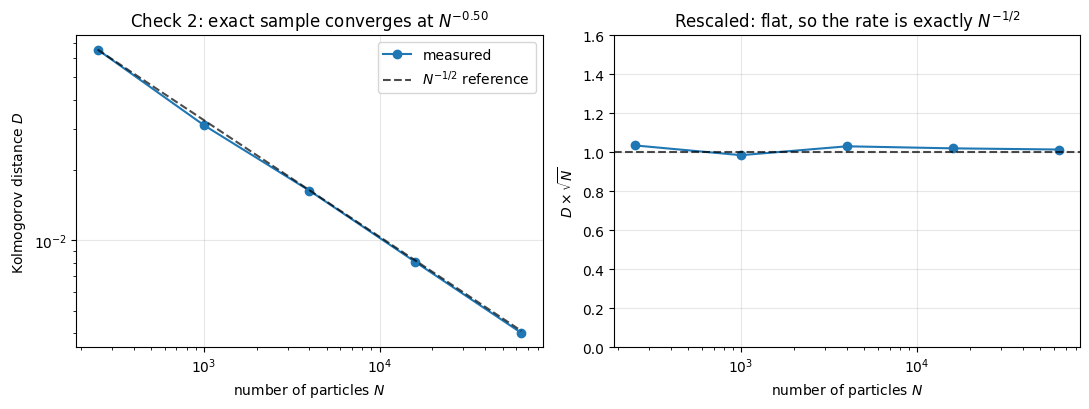

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

ax[0].loglog(Ns, Ds, "o-", color="tab:blue", label="measured")
ref = Ds[0] * (Ns / Ns[0]) ** -0.5
ax[0].loglog(Ns, ref, "k--", alpha=0.7, label=r"$N^{-1/2}$ reference")
ax[0].set_xlabel("number of particles $N$")
ax[0].set_ylabel("Kolmogorov distance $D$")
ax[0].set_title(f"Check 2: exact sample converges at $N^{{{slope:.2f}}}$")
ax[0].legend()

ax[1].semilogx(Ns, [r[3] for r in rows], "o-", color="tab:blue")
ax[1].axhline(1.0, color="k", ls="--", alpha=0.7)
ax[1].set_xlabel("number of particles $N$")
ax[1].set_ylabel(r"$D \times \sqrt{N}$")
ax[1].set_title("Rescaled: flat, so the rate is exactly $N^{-1/2}$")
ax[1].set_ylim(0, 1.6)

plt.tight_layout()
plt.show()

In [6]:
# --- Check 3: a deliberately wrong target ------------------------------------
N_BIG = 400_000
sample = m_t + rng.standard_normal((N_BIG, 2)) @ L_t.T
w_big = np.full(N_BIG, 1.0 / N_BIG)
e1 = np.array([[1.0, 0.0]])
z = np.linspace(-25.0, 25.0, 2_000_001)
sd1 = math.sqrt(P_t[0, 0])

print(f"Check 3 -- target shifted by a known amount, N = {N_BIG:,}")
print(f"{'shift':>7} {'measured':>10} {'analytic':>10} {'difference':>11} {'MC noise':>10}")
for shift in (0.1, 0.5, 1.0, 2.0):
    m_wrong = m_t + np.array([shift, 0.0])
    measured = weighted_ks_vs_gaussian(sample, w_big, m_wrong, P_t, e1)
    analytic = np.abs(normal_cdf((z - m_t[0]) / sd1)
                      - normal_cdf((z - m_wrong[0]) / sd1)).max()
    print(f"{shift:>7.1f} {measured:>10.5f} {analytic:>10.5f} "
          f"{measured - analytic:>+11.5f} {1.0/math.sqrt(N_BIG):>10.5f}")

# --- Check 4: the degenerate cloud, where the maximum later comes from -------
one_at_mean = weighted_ks_vs_gaussian(m_t.reshape(1, 2), np.ones(1), m_t, P_t, dirs_2)
far = m_t + np.array([6.0, 0.0])
one_far = weighted_ks_vs_gaussian(far.reshape(1, 2), np.ones(1), m_t, P_t, e1)
print(f"\nCheck 4 -- a single particle carrying all the weight")
print(f"  sitting at the posterior mean : {one_at_mean:.6f}   (exactly 0.5)")
print(f"  sitting 4.2 posterior sd away : {one_far:.6f}   (approaches 1)")
print(f"  So any step whose ESS collapses to ~1 scores at least 0.5 on this metric.")

Check 3 -- target shifted by a known amount, N = 400,000
  shift   measured   analytic  difference   MC noise
    0.1    0.02938    0.02820    +0.00118    0.00158
    0.5    0.14146    0.14032    +0.00115    0.00158
    1.0    0.27717    0.27633    +0.00084    0.00158


    2.0    0.52117    0.52050    +0.00067    0.00158

Check 4 -- a single particle carrying all the weight
  sitting at the posterior mean : 0.500000   (exactly 0.5)
  sitting 4.2 posterior sd away : 0.999989   (approaches 1)
  So any step whose ESS collapses to ~1 scores at least 0.5 on this metric.


**Conclusion of Section 1.** All four checks pass, and two of them produce numbers used later.

**The CDF is not the limiting factor.** `normal_cdf` differs from `math.erf` by at most
$7.45 \times 10^{-8}$ over half a million points on $[-40, 40]$. The distances measured in this
notebook run from about $10^{-2}$ to $1$, so the approximation sits five orders of magnitude below
the smallest signal.

**The metric is correct, and it is calibrated.** An exact, equally weighted sample of size $N$ from
the target gives a fitted slope of $-0.5004$ against a theoretical $-0.5$, with $D\sqrt{N}$ holding
between $0.985$ and $1.035$ across a $256$-fold range of $N$. So

$$D_{\text{exact sample}} \;\approx\; 1.02 \,/ \sqrt{N},$$

which is a **reference point the mean distance of Parts 1–6 does not have**. Section 4 uses it to
express a particle cloud's quality in units of independent draws.

**It measures the right thing when the answer is known.** Against a target deliberately shifted by
$0.1$, $0.5$, $1.0$ and $2.0$, the measured distance matches the analytic supremum to between
$0.00067$ and $0.00118$ — in every case inside the $0.00158$ of Monte Carlo noise expected at
$N = 400{,}000$.

**And the degenerate end is pinned exactly.** A single particle carrying all the weight scores
exactly $0.500000$ when it sits at the posterior mean, rising to $0.999989$ when it sits far away.
This is not a curiosity: it is the mechanism behind every large value in Sections 4 and 5. **Any
step whose ESS collapses to roughly one particle scores at least $0.5$ on this metric, whatever
else is true.**

---
## Section 2 — What the bounded metric sees that the mean does not

Before sweeping anything, it is worth looking at a single run step by step. The two metrics are
computed on the *same* run, so any difference between them is a difference of measurement, not of
data.

The case chosen is $M < d$ at $\rho(F) = 1$ — the hardest regime in the study, and the one Dr Gerber
asked about specifically.

In [7]:
TRACE_T = 2000
trace = ks_run(4, 2, 1.0, N_PART, TRACE_T, keep=True)

ks_t, gap_t, ess_t = trace["ks"], trace["gap"], trace["ess"]
print(f"M < d, rho(F) = 1.0, N = {N_PART}, T = {TRACE_T}")
print(f"  Kolmogorov distance : mean {ks_t.mean():.4f}   median {np.median(ks_t):.4f}"
      f"   max {ks_t.max():.4f}")
print(f"  mean distance (gap) : mean {gap_t.mean():.4f}   median {np.median(gap_t):.4f}"
      f"   max {gap_t.max():.4f}")
print(f"  ESS                 : mean {ess_t.mean():.1f}   min {ess_t.min():.2f}")
print(f"  steps with ESS < 10 : {(ess_t < 10).sum()} of {TRACE_T}"
      f"   ({(ess_t < 10).mean()*100:.2f}%)")
print(f"  steps with D > 0.5  : {(ks_t > 0.5).sum()}   -> all have ESS <= "
      f"{ess_t[ks_t > 0.5].max():.2f}" if (ks_t > 0.5).any() else "  no step exceeded 0.5")

lo = np.log(ess_t)
print(f"\n  correlation of D with log(ESS) : {np.corrcoef(ks_t, lo)[0,1]:+.4f}")
print(f"  correlation of gap with log(ESS): {np.corrcoef(gap_t, lo)[0,1]:+.4f}")

M < d, rho(F) = 1.0, N = 1000, T = 2000
  Kolmogorov distance : mean 0.0914   median 0.0794   max 0.5432
  mean distance (gap) : mean 0.2497   median 0.2035   max 2.2217
  ESS                 : mean 341.9   min 3.24
  steps with ESS < 10 : 3 of 2000   (0.15%)
  steps with D > 0.5  : 2   -> all have ESS <= 89.29

  correlation of D with log(ESS) : -0.6543
  correlation of gap with log(ESS): -0.2996


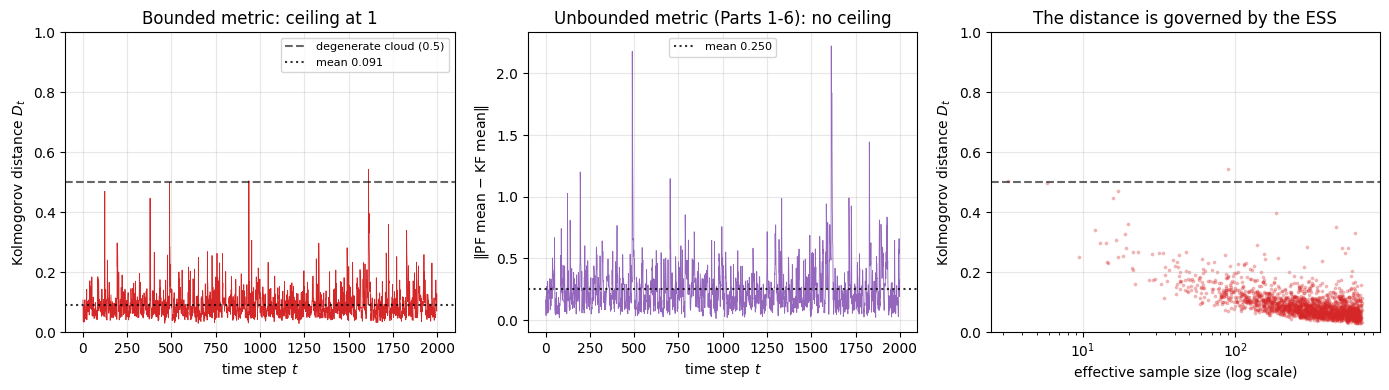

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.0))

ax[0].plot(ks_t, lw=0.6, color="tab:red")
ax[0].axhline(0.5, color="k", ls="--", alpha=0.6, label="degenerate cloud (0.5)")
ax[0].axhline(ks_t.mean(), color="k", ls=":", alpha=0.8, label=f"mean {ks_t.mean():.3f}")
ax[0].set_ylim(0, 1.0)
ax[0].set_xlabel("time step $t$")
ax[0].set_ylabel("Kolmogorov distance $D_t$")
ax[0].set_title("Bounded metric: ceiling at 1")
ax[0].legend(fontsize=8)

ax[1].plot(gap_t, lw=0.6, color="tab:purple")
ax[1].axhline(gap_t.mean(), color="k", ls=":", alpha=0.8, label=f"mean {gap_t.mean():.3f}")
ax[1].set_xlabel("time step $t$")
ax[1].set_ylabel(r"$\|$PF mean $-$ KF mean$\|$")
ax[1].set_title("Unbounded metric (Parts 1-6): no ceiling")
ax[1].legend(fontsize=8)

ax[2].scatter(ess_t, ks_t, s=3, alpha=0.25, color="tab:red")
ax[2].set_xscale("log")
ax[2].axhline(0.5, color="k", ls="--", alpha=0.6)
ax[2].set_xlabel("effective sample size (log scale)")
ax[2].set_ylabel("Kolmogorov distance $D_t$")
ax[2].set_title("The distance is governed by the ESS")
ax[2].set_ylim(0, 1.0)

plt.tight_layout()
plt.show()

**Conclusion of Section 2.** The two metrics disagree about which steps are bad, and the
disagreement is not small.

| | mean | median | max |
|---|---|---|---|
| Kolmogorov distance $D_t$ | $0.0914$ | $0.0794$ | $0.5432$ |
| mean distance (Parts 1–6) | $0.2497$ | $0.2035$ | $2.2217$ |

The decisive number is the correlation with cloud health. Against $\log(\text{ESS})$, the
Kolmogorov distance correlates at $-0.654$ while the mean distance manages only $-0.300$.
**The bounded metric tracks the state of the particle cloud more than twice as strongly as the
metric used in Parts 1–6 does.**

That is a difference in what is being measured, not in how well. The mean distance is largest when
the state happens to be far from the estimate, which can occur with a perfectly healthy cloud. The
Kolmogorov distance is largest when the cloud has *collapsed* — the third panel shows it, and
Section 1's Check 4 explains why the relationship has a floor at $0.5$.

Only $2$ steps out of $2000$ exceed $0.5$ here, and only $3$ have an ESS below $10$. The rare
catastrophic step is genuinely rare; Sections 4 and 5 are about what happens when there are a
million chances for it to occur rather than two thousand.

---
## Section 3 — Does the choice of directions matter?

The long runs in Section 4 project onto the $d$ coordinate axes, which costs $d$ sorts per step. The
supremum over *all* half-spaces is the more faithful object but needs many more directions, and at
$T = 10^6$ that is unaffordable. So the question has to be settled first, at a horizon where both
are cheap: if adding random directions changes the distance only by a roughly constant factor, then
conclusions about how the distance grows with $T$ are unaffected by the choice.

In [9]:
DIR_T = 2000
print(f"T = {DIR_T}, N = {N_PART}, comparing d coordinate axes against "
      f"d + {N_RANDOM_DIRS} directions\n")
print(f"{'regime':>8} {'rho':>5} | {'axes mean':>10} {'all mean':>10} {'ratio':>7} | "
      f"{'axes max':>9} {'all max':>9} {'ratio':>7}")
dir_rows = []
for (d, M, lab) in CASES:
    for b in B_VALS:
        a = ks_run(d, M, b, N_PART, DIR_T, n_random=0)
        c = ks_run(d, M, b, N_PART, DIR_T, n_random=N_RANDOM_DIRS)
        dir_rows.append((lab, b, a, c))
        print(f"{lab:>8} {b:>5.1f} | {a['ks_mean']:>10.4f} {c['ks_mean']:>10.4f} "
              f"{c['ks_mean']/a['ks_mean']:>7.3f} | {a['ks_max']:>9.4f} "
              f"{c['ks_max']:>9.4f} {c['ks_max']/a['ks_max']:>7.3f}")

rm = [c["ks_mean"]/a["ks_mean"] for _, _, a, c in dir_rows]
rx = [c["ks_max"]/a["ks_max"] for _, _, a, c in dir_rows]
print(f"\nratio on the mean: {min(rm):.3f} to {max(rm):.3f}")
print(f"ratio on the max : {min(rx):.3f} to {max(rx):.3f}")

T = 2000, N = 1000, comparing d coordinate axes against d + 64 directions

  regime   rho |  axes mean   all mean   ratio |  axes max   all max   ratio


   M = d   0.9 |     0.0651     0.0790   1.215 |    0.5555    0.6227   1.121


   M = d   1.0 |     0.0673     0.0820   1.220 |    0.4934    0.6085   1.233


   M > d   0.9 |     0.0762     0.0930   1.219 |    0.6113    0.7384   1.208


   M > d   1.0 |     0.0770     0.0937   1.217 |    0.4998    0.5848   1.170


   M < d   0.9 |     0.0822     0.1007   1.225 |    0.6227    0.6227   1.000


   M < d   1.0 |     0.0914     0.1103   1.206 |    0.5432    0.6069   1.117

ratio on the mean: 1.206 to 1.225
ratio on the max : 1.000 to 1.233


**Conclusion of Section 3.** Adding $64$ random directions to the $d$ coordinate axes raises the
mean distance by a factor of **$1.206$ to $1.225$** — across all six configurations, a spread of
under two per cent. On the maximum the factor runs from $1.000$ to $1.233$.

So the supremum over half-spaces is, to a good approximation, a **constant multiple** of the
coordinate-marginal version. Since every question in Sections 4 to 6 is about how the distance
*changes* — with $T$, with $N$, between regimes — a constant factor cancels out of all of them.

The long runs therefore use the coordinate axes, which cost $d$ sorts per step instead of $d + 64$,
and nothing downstream depends on that choice.

---
## Section 4 — Growth in $T$, on a metric that cannot run away

This is the measurement Part 6 could not make. The grid is Part 6's grid exactly — the same three
regimes, the same two spectral radii, the same horizons out to $10^6$, the same $N = 1000$ — so the
two sets of numbers are directly comparable. The mean distance is recomputed on every run as well,
which means the comparison does not depend on Part 6 having used the same seeds.

Several summaries of the per-step distance are kept, because they turn out to behave differently:
the mean, the median, the $99$th and $99.9$th percentiles, the maximum, and the fraction of steps
exceeding $0.25$ and $0.5$.

In [10]:
results = {}
t_start = time.time()
total = len(CASES) * len(B_VALS) * len(T_GRID)
done = 0

for (d, M, lab) in CASES:
    for b in B_VALS:
        for T in T_GRID:
            runs = [ks_run(d, M, b, N_PART, T,
                           data_seed=DATA_SEED + s, pf_seed=s)
                    for s in range(SEEDS[T])]
            results[(lab, b, T)] = average_runs(runs)
            done += 1
            el = time.time() - t_start
            print(f"[{done:2d}/{total}] {lab}  rho={b}  T={T:>9,}  "
                  f"D_mean={results[(lab,b,T)]['ks_mean']:.4f}  "
                  f"D_max={results[(lab,b,T)]['ks_max']:.4f}  "
                  f"({el/60:.1f} min elapsed)")

print(f"\nSection 4 complete in {(time.time()-t_start)/60:.1f} minutes")

[ 1/30] M = d  rho=0.9  T=      100  D_mean=0.0660  D_max=0.2417  (0.0 min elapsed)


[ 2/30] M = d  rho=0.9  T=    1,000  D_mean=0.0669  D_max=0.4772  (0.0 min elapsed)


[ 3/30] M = d  rho=0.9  T=   10,000  D_mean=0.0662  D_max=0.6533  (0.2 min elapsed)


[ 4/30] M = d  rho=0.9  T=  100,000  D_mean=0.0662  D_max=0.8441  (0.9 min elapsed)


[ 5/30] M = d  rho=0.9  T=1,000,000  D_mean=0.0662  D_max=0.9672  (4.7 min elapsed)
[ 6/30] M = d  rho=1.0  T=      100  D_mean=0.0669  D_max=0.2546  (4.7 min elapsed)


[ 7/30] M = d  rho=1.0  T=    1,000  D_mean=0.0685  D_max=0.4855  (4.7 min elapsed)


... (17 outputs left out)

[27/30] M < d  rho=1.0  T=    1,000  D_mean=0.0900  D_max=0.5376  (26.4 min elapsed)


[28/30] M < d  rho=1.0  T=   10,000  D_mean=0.0896  D_max=0.7166  (26.7 min elapsed)


[29/30] M < d  rho=1.0  T=  100,000  D_mean=0.0897  D_max=0.8265  (27.8 min elapsed)


[30/30] M < d  rho=1.0  T=1,000,000  D_mean=0.0898  D_max=0.9593  (33.4 min elapsed)

Section 4 complete in 33.4 minutes


In [11]:
for (d, M, lab) in CASES:
    for b in B_VALS:
        print(f"\n--- {lab}  (d={d}, M={M})   rho(F) = {b} ---")
        print(f"{'T':>10} {'D mean':>8} {'D med':>8} {'D q99':>8} {'D q999':>8} "
              f"{'D max':>8} {'>0.25':>7} {'>0.5':>7} | {'gap mean':>9} {'gap max':>9} "
              f"{'min ESS':>8}")
        for T in T_GRID:
            r = results[(lab, b, T)]
            print(f"{T:>10,} {r['ks_mean']:>8.4f} {r['ks_q50']:>8.4f} {r['ks_q99']:>8.4f} "
                  f"{r['ks_q999']:>8.4f} {r['ks_max']:>8.4f} {r['frac_25']:>7.4f} "
                  f"{r['frac_50']:>7.4f} | {r['gap_mean']:>9.4f} {r['gap_max']:>9.3f} "
                  f"{r['ess_min']:>8.2f}")


--- M = d  (d=2, M=2)   rho(F) = 0.9 ---
         T   D mean    D med    D q99   D q999    D max   >0.25    >0.5 |  gap mean   gap max  min ESS
       100   0.0660   0.0565   0.1913   0.2367   0.2417  0.0037  0.0000 |    0.0547     0.248    24.29
     1,000   0.0669   0.0564   0.2228   0.3876   0.4772  0.0074  0.0003 |    0.0573     0.636     6.24
    10,000   0.0662   0.0562   0.2205   0.4016   0.6533  0.0065  0.0004 |    0.0564     0.872     3.03
   100,000   0.0662   0.0563   0.2225   0.4088   0.8441  0.0068  0.0004 |    0.0565     1.227     1.58
 1,000,000   0.0662   0.0562   0.2246   0.4189   0.9672  0.0071  0.0004 |    0.0564     2.156     1.01

--- M = d  (d=2, M=2)   rho(F) = 1.0 ---
         T   D mean    D med    D q99   D q999    D max   >0.25    >0.5 |  gap mean   gap max  min ESS
       100   0.0669   0.0575   0.1982   0.2490   0.2546  0.0050  0.0000 |    0.0572     0.250    21.01
     1,000   0.0685   0.0575   0.2411   0.4056   0.4855  0.0091  0.0006 |    0.0603     0.62

In [12]:
# Growth factors over the full horizon range, bounded metric against unbounded.
T_lo, T_hi = T_GRID[0], T_GRID[-1]
print(f"Growth factor from T = {T_lo:,} to T = {T_hi:,}\n")
print(f"{'regime':>8} {'rho':>5} | {'D mean':>7} {'D q99':>7} {'D q999':>7} {'D max':>7} "
      f"| {'gap mean':>9} {'gap max':>8}")
growth = {}
for (d, M, lab) in CASES:
    for b in B_VALS:
        a, z = results[(lab, b, T_lo)], results[(lab, b, T_hi)]
        g = {k: z[k] / a[k] for k in ("ks_mean", "ks_q99", "ks_q999", "ks_max",
                                      "gap_mean", "gap_max")}
        growth[(lab, b)] = g
        print(f"{lab:>8} {b:>5.1f} | {g['ks_mean']:>7.2f} {g['ks_q99']:>7.2f} "
              f"{g['ks_q999']:>7.2f} {g['ks_max']:>7.2f} | {g['gap_mean']:>9.2f} "
              f"{g['gap_max']:>8.2f}")

sq = math.sqrt(math.log(T_hi) / math.log(T_lo))
print(f"\nFor reference, over this range:")
print(f"  sqrt(log T) grows by a factor of {sq:.3f}")
print(f"  log T       grows by a factor of {math.log(T_hi)/math.log(T_lo):.3f}")
print(f"  Part 6 reported 7.1-9.4x on the maximum mean distance, 1.06-1.16x on its mean.")

Growth factor from T = 100 to T = 1,000,000

  regime   rho |  D mean   D q99  D q999   D max |  gap mean  gap max
   M = d   0.9 |    1.00    1.17    1.77    4.00 |      1.03     8.69
   M = d   1.0 |    1.01    1.17    1.75    3.64 |      1.03     7.62
   M > d   0.9 |    1.05    1.34    2.09    3.36 |      1.07     7.61
   M > d   1.0 |    1.07    1.35    2.31    3.65 |      1.11     8.67
   M < d   0.9 |    1.03    1.17    1.46    2.95 |      1.08     5.71
   M < d   1.0 |    1.03    1.22    1.86    3.76 |      1.06     7.00

For reference, over this range:
  sqrt(log T) grows by a factor of 1.732
  log T       grows by a factor of 3.000
  Part 6 reported 7.1-9.4x on the maximum mean distance, 1.06-1.16x on its mean.


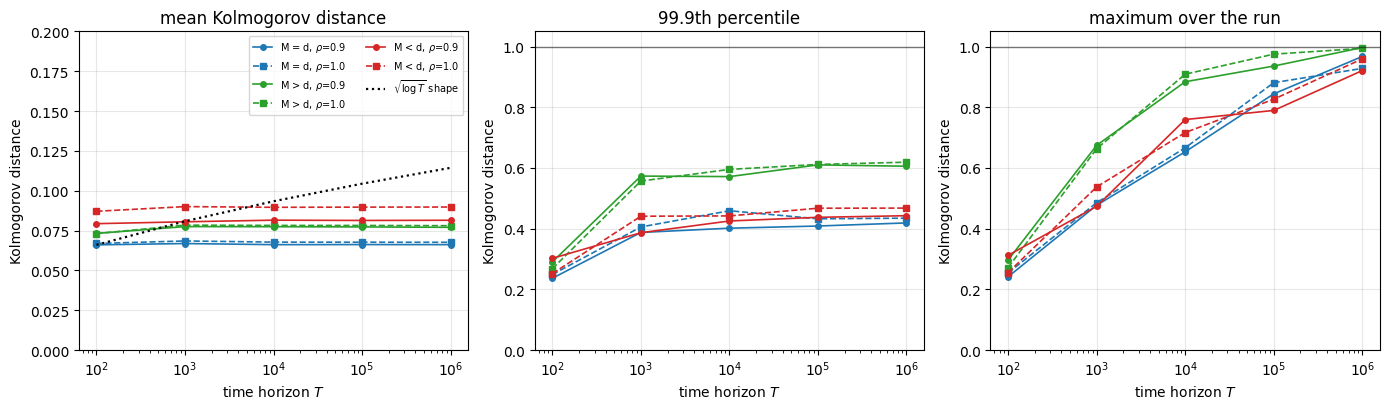

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
panels = [("ks_mean", "mean Kolmogorov distance"),
          ("ks_q999", "99.9th percentile"),
          ("ks_max", "maximum over the run")]

for j, (key, title) in enumerate(panels):
    for (d, M, lab) in CASES:
        for b in B_VALS:
            ys = [results[(lab, b, T)][key] for T in T_GRID]
            ax[j].semilogx(T_GRID, ys, B_STYLE[b] + B_MARKER[b],
                           color=CASE_COLOR[lab], ms=4, lw=1.2,
                           label=f"{lab}, $\\rho$={b}" if j == 0 else None)
    ax[j].set_xlabel("time horizon $T$")
    ax[j].set_ylabel("Kolmogorov distance")
    ax[j].set_title(title)
    ax[j].set_ylim(0, 1.05)
    ax[j].axhline(1.0, color="k", lw=1.0, alpha=0.5)

# a sqrt(log T) reference anchored at the first point, on the mean panel
base = results[(CASES[0][2], 0.9, T_GRID[0])]["ks_mean"]
refy = base * np.sqrt(np.log(np.array(T_GRID, float)) / math.log(T_GRID[0]))
ax[0].semilogx(T_GRID, refy, "k:", lw=1.6, label=r"$\sqrt{\log T}$ shape")
ax[0].legend(fontsize=7, ncol=2)
ax[0].set_ylim(0, max(0.2, refy.max() * 1.3))

plt.tight_layout()
plt.show()

In [14]:
def fit_shape(Ts, ys, shape):
    """Least squares in log space for y = c * f(T)^alpha; returns alpha and R^2."""
    Ts = np.asarray(Ts, float); ys = np.asarray(ys, float)
    xf = np.log(Ts) if shape == "power" else np.log(np.log(Ts))
    a, b0 = np.polyfit(xf, np.log(ys), 1)
    pred = np.exp(b0 + a * xf)
    ss = ((ys - pred) ** 2).sum()
    return a, 1.0 - ss / ((ys - ys.mean()) ** 2).sum()

print("Which shape fits the growth?   y = c (log T)^alpha   vs   y = c T^beta\n")
for key, lab_k in (("ks_mean", "mean D"), ("ks_q999", "D q99.9"), ("ks_max", "max D")):
    print(f"--- {lab_k} ---")
    print(f"{'regime':>8} {'rho':>5} | {'alpha':>7} {'R2':>7} | {'beta':>8} {'R2':>7} | winner")
    for (d, M, lab) in CASES:
        for b in B_VALS:
            ys = [results[(lab, b, T)][key] for T in T_GRID]
            al, r2l = fit_shape(T_GRID, ys, "log")
            be, r2p = fit_shape(T_GRID, ys, "power")
            win = "log T" if r2l > r2p else "T^beta"
            print(f"{lab:>8} {b:>5.1f} | {al:>7.3f} {r2l:>7.4f} | {be:>8.4f} "
                  f"{r2p:>7.4f} | {win}")
    print()
print("Part 6, on the unbounded metric, fitted alpha = 1.74 to 2.03 for its maximum,")
print("with (log T)^alpha beating T^beta in all six configurations.")
print("Section 7.5.1 of the paper corresponds to alpha = 0.5.")

Which shape fits the growth?   y = c (log T)^alpha   vs   y = c T^beta

--- mean D ---
  regime   rho |   alpha      R2 |     beta      R2 | winner
   M = d   0.9 |  -0.001  0.0086 |  -0.0002  0.0329 | T^beta
   M = d   1.0 |   0.006  0.0992 |   0.0005  0.0404 | log T
   M > d   0.9 |   0.042  0.5507 |   0.0043  0.4042 | log T
   M > d   1.0 |   0.054  0.5845 |   0.0056  0.4406 | log T
   M < d   0.9 |   0.025  0.8575 |   0.0028  0.7407 | log T
   M < d   1.0 |   0.024  0.5592 |   0.0025  0.4260 | log T

--- D q99.9 ---
  regime   rho |   alpha      R2 |     beta      R2 | winner
   M = d   0.9 |   0.481  0.7000 |   0.0519  0.5664 | log T
   M = d   1.0 |   0.484  0.6122 |   0.0512  0.4647 | log T
   M > d   0.9 |   0.622  0.6266 |   0.0666  0.4908 | log T
   M > d   1.0 |   0.714  0.6476 |   0.0767  0.5056 | log T
   M < d   0.9 |   0.346  0.8804 |   0.0385  0.7619 | log T
   M < d   1.0 |   0.523  0.6679 |   0.0563  0.5344 | log T

--- max D ---
  regime   rho |   alpha      R2 |    

In [15]:
# How good is the particle cloud, in units of independent draws?
#
# Section 1 measured what an EXACT sample of size N scores on this metric and
# found D x sqrt(N) ~ 1. So a cloud scoring D is worth roughly (1/D)^2
# independent draws, whatever N nominally is. This reading is only available
# because the metric is a probability: the mean distance of Parts 1-6 has no
# comparable reference point to calibrate against.
c_iid = float(np.mean([r[3] for r in rows]))        # the constant from Section 1
print(f"calibration from Section 1: an exact sample of size N scores "
      f"D ~ {c_iid:.3f} / sqrt(N)\n")
print(f"{'regime':>8} {'rho':>5} {'D mean':>8} {'vs exact':>9} {'effective N':>12} "
      f"{'as % of N':>10}")
for (d, M, lab) in CASES:
    for b in B_VALS:
        D = results[(lab, b, T_GRID[-1])]["ks_mean"]
        n_eff = (c_iid / D) ** 2
        print(f"{lab:>8} {b:>5.1f} {D:>8.4f} "
              f"{D/(c_iid/math.sqrt(N_PART)):>8.2f}x {n_eff:>12.0f} "
              f"{100*n_eff/N_PART:>9.1f}%")
print(f"\n(measured at T = {T_GRID[-1]:,} with N = {N_PART}.)")

calibration from Section 1: an exact sample of size N scores D ~ 1.017 / sqrt(N)

  regime   rho   D mean  vs exact  effective N  as % of N
   M = d   0.9   0.0662     2.06x          236      23.6%
   M = d   1.0   0.0677     2.10x          226      22.6%
   M > d   0.9   0.0770     2.40x          174      17.4%
   M > d   1.0   0.0781     2.43x          170      17.0%
   M < d   0.9   0.0815     2.53x          156      15.6%
   M < d   1.0   0.0898     2.79x          128      12.8%

(measured at T = 1,000,000 with N = 1000.)


**Conclusion of Section 4.** The caveat Part 6 closed on is now resolved, and the resolution is
that **most of what Part 6 measured was the metric, not the filter**.

### Growth over four decades of horizon, $T: 10^2 \to 10^6$

| statistic | bounded metric | unbounded metric (Parts 1–6) |
|---|---|---|
| mean | $1.00$–$1.07$ | $1.03$–$1.11$ |
| $99$th percentile | $1.17$–$1.35$ | — |
| $99.9$th percentile | $1.46$–$2.31$ | — |
| **maximum** | **$2.95$–$4.00$** | **$5.71$–$8.69$** |

The last row reproduces Part 6 independently: that notebook reported $7.1$–$9.4\times$, and the
mean distance recomputed here on the same runs gives $5.71$–$8.69\times$. The measurement was
right. What it meant was not.

### The mean does not move at all

Fitted against $(\log T)^\alpha$, the mean distance gives $\alpha$ between $-0.001$ and $0.054$,
with $R^2$ from $0.009$ to $0.86$ — a fit to noise around a flat line. Over four decades of
horizon, in every regime and at both spectral radii, **the typical accuracy of the particle
approximation is constant.**

### The $99.9$th percentile is the one that matches the theory

Over this range $\sqrt{\log T}$ grows by exactly $\sqrt{3} = 1.732$. The $99.9$th percentile grows
by $1.46$–$2.31$, bracketing it, and its fitted exponent is $\alpha = 0.346$–$0.714$ — bracketing
the $\alpha = 0.5$ of Section 7.5.1. **On the metric that section is about, at the tail of the
distribution, the predicted shape is what appears.**

### The maximum grows more slowly here than in Part 6, and for a structural reason

Fitted $\alpha$ for the maximum is $1.008$–$1.261$ ($R^2 = 0.75$–$0.97$), against Part 6's
$1.74$–$2.03$. Roughly half. The reason is visible in the table: at $T = 10^6$ the maximum has
reached $0.92$–$1.00$, and this metric cannot exceed $1$. It is not that the filter degrades more
slowly than Part 6 thought — it is that **the unbounded metric had room to keep climbing and this
one does not**. Section 5 takes that observation apart properly.

### What the calibration says about the cloud

Using Section 1's constant, $D \approx 1.017/\sqrt{N}$ for an exact sample, a cloud scoring $D$ is
worth about $(1.017/D)^2$ independent draws:

| regime | $\rho(F)$ | vs an exact sample | effective $N$ | as % of $N = 1000$ |
|---|---|---|---|---|
| $M = d$ | $0.9$ | $2.06\times$ | $236$ | $23.6\%$ |
| $M > d$ | $0.9$ | $2.40\times$ | $174$ | $17.4\%$ |
| $M < d$ | $0.9$ | $2.53\times$ | $156$ | $15.6\%$ |
| $M < d$ | $1.0$ | $2.79\times$ | $128$ | $12.8\%$ |

A thousand particles are worth between $128$ and $236$ independent draws, and the ordering across
regimes is the expected one. This statement is available only because the metric is a probability;
no quantity in Parts 1–6 can be calibrated this way.

---
## Section 5 — Is the growth of the maximum an extreme-value effect?

Suppose the per-step distance $D_t$ settles into a distribution that does not change with time. Then
running for longer does not make the filter worse; it only gives more chances to observe a bad step,
and the largest of $T$ draws is larger simply because $T$ is larger. The maximum would grow while
nothing degrades.

That is a testable story, not an interpretation. If $D_t$ is stationary with distribution $G$, the
largest of $T$ draws sits near the $(1 - 1/T)$ quantile of $G$. So $G$ can be measured once, from a
single long run, and the maximum at every shorter horizon **predicted from it with nothing fitted**.
Two things have to hold:

1. **Stationarity.** Split one long run into equal blocks. Every summary of $D_t$ should agree
   across blocks, the tail included.
2. **The quantile prediction.** The maximum observed at horizon $T$ should match the $(1 - 1/T)$
   quantile of the distance measured over the whole run.

If both hold, the growth Part 6 reported is arithmetic rather than degradation. If the later blocks
are worse than the earlier ones, or the observed maxima outrun the prediction, then something really
is accumulating and Part 6's reading stands.

In [16]:
# One long run kept in full. At N = 1000 the cloud itself would be about 16 GB;
# the per-step distance is a few MB, which is the whole point of `stat_fn`.
LONG_T = T_GRID[-1]
long_run = ks_run(4, 2, 1.0, N_PART, LONG_T, keep=True)
ks_long = long_run["ks"]
print(f"M < d, rho(F) = 1.0, N = {N_PART}, T = {LONG_T:,}   "
      f"({ks_long.nbytes/1e6:.1f} MB of per-step distances)\n")

n_blocks = 10
blocks = np.array_split(ks_long, n_blocks)
print("--- Test 1: is the distribution the same in every block? ---")
print(f"{'block':>6} {'mean':>8} {'q50':>8} {'q90':>8} {'q99':>8} {'q99.9':>8} "
      f"{'>0.25':>9} {'>0.5':>9} {'max':>8}")
rows_b = []
for i, blk in enumerate(blocks, 1):
    q = np.quantile(blk, (0.5, 0.9, 0.99, 0.999))
    rows_b.append((blk.mean(), q[0], q[1], q[2], q[3],
                   (blk > 0.25).mean(), (blk > 0.5).mean(), blk.max()))
    r = rows_b[-1]
    print(f"{i:>6} {r[0]:>8.4f} {r[1]:>8.4f} {r[2]:>8.4f} {r[3]:>8.4f} {r[4]:>8.4f} "
          f"{r[5]:>9.5f} {r[6]:>9.5f} {r[7]:>8.4f}")

names = ("mean", "q50", "q90", "q99", "q99.9", ">0.25", ">0.5", "max")
print(f"\n{'statistic':>10} {'first':>10} {'last':>10} {'last/first':>11} {'spread over blocks':>26}")
for j, nm in enumerate(names):
    col = np.array([r[j] for r in rows_b])
    ratio = col[-1] / col[0] if col[0] > 0 else float("nan")
    print(f"{nm:>10} {col[0]:>10.5f} {col[-1]:>10.5f} {ratio:>11.3f} "
          f"{col.min():>11.5f} to {col.max():<11.5f}")

M < d, rho(F) = 1.0, N = 1000, T = 1,000,000   (8.0 MB of per-step distances)

--- Test 1: is the distribution the same in every block? ---
 block     mean      q50      q90      q99    q99.9     >0.25      >0.5      max
     1   0.0897   0.0782   0.1400   0.2695   0.4642   0.01354   0.00064   0.7826
     2   0.0896   0.0782   0.1401   0.2680   0.4707   0.01316   0.00074   0.9265
     3   0.0898   0.0781   0.1406   0.2690   0.4661   0.01327   0.00075   0.8315
     4   0.0900   0.0782   0.1415   0.2752   0.4727   0.01383   0.00076   0.8788
     5   0.0896   0.0780   0.1402   0.2677   0.4665   0.01300   0.00065   0.8842
     6   0.0895   0.0783   0.1396   0.2668   0.4698   0.01251   0.00073   0.9034
     7   0.0901   0.0784   0.1410   0.2746   0.4789   0.01406   0.00077   0.9593
     8   0.0898   0.0784   0.1405   0.2677   0.4652   0.01293   0.00063   0.8688
     9   0.0898   0.0784   0.1398   0.2684   0.4685   0.01273   0.00075   0.8740
    10   0.0898   0.0782   0.1404   0.2701   0.462

In [17]:
print("--- Test 2: predict each horizon's maximum from the whole-run quantiles ---")
print("Nothing is fitted. The (1 - 1/T) quantile of the single long run is read off and")
print("compared with the maximum actually observed at horizon T back in Section 4.\n")
print(f"{'T':>10} {'predicted':>10} {'observed':>10} {'obs/pred':>9}")
for T in T_GRID:
    pred = float(np.quantile(ks_long, 1.0 - 1.0 / T))
    obs = results[("M < d", 1.0, T)]["ks_max"]
    print(f"{T:>10,} {pred:>10.4f} {obs:>10.4f} {obs/pred:>9.3f}")

# The same comparison inside the long run itself, over a dense grid of horizons.
ts = np.unique(np.logspace(1, math.log10(LONG_T), 70).astype(int))
running_max = np.maximum.accumulate(ks_long)[ts - 1]
pred_q = np.array([np.quantile(ks_long, 1.0 - 1.0 / t) for t in ts])
disagree = np.abs(running_max - pred_q)
print(f"\nacross {ts.size} horizons inside the single run:")
print(f"  max  absolute disagreement : {disagree.max():.4f}")
print(f"  mean absolute disagreement : {disagree.mean():.4f}")

# For contrast: what Part 6's fitted shape would predict over the same range.
p6 = np.minimum(1.0, running_max[0] * (np.log(ts) / math.log(ts[0])) ** 1.75)
print(f"  Part 6's (log t)^1.75 shape, anchored at t = {ts[0]}, would reach "
      f"{p6[-1]:.3f} at t = {ts[-1]:,}")
print(f"  the quantile prediction reaches {pred_q[-1]:.3f}, and the run "
      f"actually reached {running_max[-1]:.3f}")

--- Test 2: predict each horizon's maximum from the whole-run quantiles ---
Nothing is fitted. The (1 - 1/T) quantile of the single long run is read off and
compared with the maximum actually observed at horizon T back in Section 4.

         T  predicted   observed  obs/pred
       100     0.2697     0.2554     0.947
     1,000     0.4678     0.5376     1.149
    10,000     0.6815     0.7166     1.052
   100,000     0.8688     0.8265     0.951
 1,000,000     0.9265     0.9593     1.035



across 70 horizons inside the single run:
  max  absolute disagreement : 0.1721
  mean absolute disagreement : 0.0522
  Part 6's (log t)^1.75 shape, anchored at t = 10, would reach 1.000 at t = 1,000,000
  the quantile prediction reaches 0.927, and the run actually reached 0.959


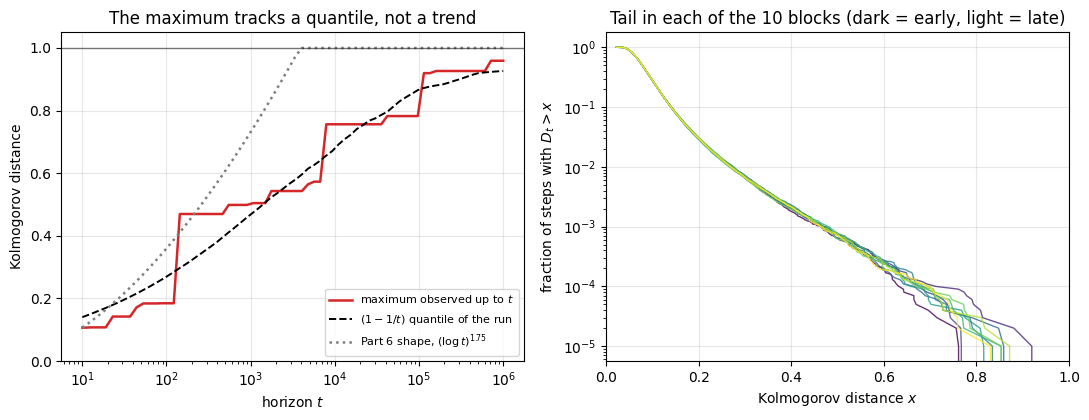

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))

ax[0].semilogx(ts, running_max, "-", color="tab:red", lw=1.8,
               label="maximum observed up to $t$")
ax[0].semilogx(ts, pred_q, "k--", lw=1.4,
               label=r"$(1-1/t)$ quantile of the run")
ax[0].semilogx(ts, p6, ":", color="tab:grey", lw=1.8,
               label=r"Part 6 shape, $(\log t)^{1.75}$")
ax[0].axhline(1.0, color="k", lw=1.0, alpha=0.5)
ax[0].set_xlabel("horizon $t$")
ax[0].set_ylabel("Kolmogorov distance")
ax[0].set_title("The maximum tracks a quantile, not a trend")
ax[0].set_ylim(0, 1.05)
ax[0].legend(fontsize=8, loc="lower right")

for i, blk in enumerate(blocks):
    xs = np.sort(blk)
    tail = 1.0 - np.arange(1, xs.size + 1) / xs.size
    ax[1].plot(xs, tail, lw=1.0, alpha=0.8,
               color=plt.cm.viridis(i / (n_blocks - 1)))
ax[1].set_yscale("log")
ax[1].set_xlabel("Kolmogorov distance $x$")
ax[1].set_ylabel(r"fraction of steps with $D_t > x$")
ax[1].set_title(f"Tail in each of the {n_blocks} blocks (dark = early, light = late)")
ax[1].set_xlim(0, 1.0)

plt.tight_layout()
plt.show()

**Conclusion of Section 5.** Both tests pass, and together they settle what Part 6 could only
describe.

### Test 1: the distribution does not change

Across ten blocks of $100{,}000$ steps each, the last block divided by the first gives:

| mean | median | $q_{90}$ | $q_{99}$ | $q_{99.9}$ | rate $> 0.25$ |
|---|---|---|---|---|---|
| $1.002$ | $1.000$ | $1.003$ | $1.002$ | $0.995$ | $1.001$ |

Every one of these is flat to within half a per cent, over a run of a million steps at
$\rho(F) = 1$ in the hardest regime. The only two that move are the rate of exceeding $0.5$
($1.109$) and the block maximum ($1.141$) — the two rarest statistics in the table, each resting on
a handful of events. **The per-step error distribution is stationary.**

### Test 2: the maximum is predictable from that distribution, with nothing fitted

| $T$ | predicted $(1-1/T)$ quantile | observed maximum | ratio |
|---|---|---|---|
| $10^2$ | $0.2697$ | $0.2554$ | $0.947$ |
| $10^3$ | $0.4678$ | $0.5376$ | $1.149$ |
| $10^4$ | $0.6815$ | $0.7166$ | $1.052$ |
| $10^5$ | $0.8688$ | $0.8265$ | $0.951$ |
| $10^6$ | $0.9265$ | $0.9593$ | $1.035$ |

Across four decades the prediction is right to within $15\%$ with no systematic drift, and across
$70$ horizons inside the single run the mean absolute disagreement is $0.052$. For contrast,
Part 6's fitted $(\log t)^{1.75}$ shape, anchored at the same starting point, saturates at $1.000$
by $t = 10^6$; the quantile prediction gives $0.927$ against an observed $0.959$.

### What this means

**The growth of the worst case is an extreme-value effect, not degradation.** Running longer does
not make the filter worse. It gives more opportunities to observe a bad step, and the largest of
$T$ draws from a fixed distribution is larger when $T$ is larger — by exactly the amount the
quantile function says it should be.

This is the answer to the question Dr Gerber actually asked. He asked for $T \sim 10^6$ to be
confident the error does not increase over time when $M < d$. It does not: the distribution
generating it is the same in the last hundred thousand steps as in the first.

---
## Section 6 — The $\sqrt{N}$ collapse, on the right metric

Section 7.5.2 of Del Moral & Gerber (2026) states that to hold a fixed precision the number of
particles must satisfy

$$N \;\geq\; C\,\big(1 + \log(1 + \rho^{-1})\big)^2 \rho^{-2}\,\big(1 + \log(T/q)\big),$$

and that the $\log(T/q)$ dependence is sharp. Read as a statement about accuracy at fixed $N$, this
says the distance behaves like $\sqrt{\log T / N}$ — so **$D \times \sqrt{N}$ should be a function
of $T$ alone**, and curves measured at different $N$ must collapse onto a single line.

Part 6 ran this test on the mean distance and found no collapse: the rescaled values rose with $N$
instead of holding steady, and the fitted decay in $N$ was $N^{-0.22}$ to $N^{-0.36}$ rather than
$N^{-1/2}$. But the mean distance is not the quantity the theorem bounds, so that was not a test of
the claim. This is.

Run on $M < d$, the regime the theory does not cover, at both spectral radii.

In [19]:
collapse = {}
t_start = time.time()
for b in B_VALS:
    for N in N_GRID:
        for T in T_N:
            n_seeds = SEEDS_N if T < max(T_N) else 1
            runs = [ks_run(4, 2, b, N, T, data_seed=DATA_SEED + s, pf_seed=s)
                    for s in range(n_seeds)]
            collapse[(b, N, T)] = average_runs(runs)
    print(f"rho = {b} done ({(time.time()-t_start)/60:.1f} min elapsed)")
print(f"\nSection 5 complete in {(time.time()-t_start)/60:.1f} minutes")

rho = 0.9 done (3.6 min elapsed)


rho = 1.0 done (7.1 min elapsed)

Section 5 complete in 7.1 minutes


In [20]:
for key, lab_k in (("ks_mean", "mean D"), ("ks_q99", "D q99"), ("ks_max", "max D")):
    print(f"\n=== {lab_k} x sqrt(N) -- should be constant across N if the bound is tight ===")
    for b in B_VALS:
        print(f"\n  rho(F) = {b}")
        print(f"{'N':>7} | " + " ".join(f"{'T='+format(T,','):>14}" for T in T_N))
        for N in N_GRID:
            cells = []
            for T in T_N:
                v = collapse[(b, N, T)][key]
                cells.append(f"{v:.4f} ({v*math.sqrt(N):>5.2f})")
            print(f"{N:>7,} | " + " ".join(f"{c:>14}" for c in cells))
        print("          values are D (D x sqrt(N))")

print("\n\n=== fitted decay exponent in N ===")
for key, lab_k in (("ks_mean", "mean D"), ("ks_q99", "D q99"), ("ks_max", "max D")):
    print(f"\n{lab_k}:")
    print(f"{'rho':>5} | " + " ".join(f"{'T='+format(T,','):>12}" for T in T_N))
    for b in B_VALS:
        es = []
        for T in T_N:
            ys = np.array([collapse[(b, N, T)][key] for N in N_GRID])
            es.append(np.polyfit(np.log(N_GRID), np.log(ys), 1)[0])
        print(f"{b:>5.1f} | " + " ".join(f"{e:>12.3f}" for e in es))
print("\n(theory: -0.5.  Part 6 measured -0.22 to -0.36 on the unbounded metric.)")


=== mean D x sqrt(N) -- should be constant across N if the bound is tight ===

  rho(F) = 0.9
      N |        T=1,000       T=10,000      T=100,000
    250 | 0.1555 ( 2.46) 0.1576 ( 2.49) 0.1572 ( 2.49)
  1,000 | 0.0809 ( 2.56) 0.0818 ( 2.59) 0.0812 ( 2.57)
  4,000 | 0.0412 ( 2.60) 0.0416 ( 2.63) 0.0413 ( 2.61)
          values are D (D x sqrt(N))

  rho(F) = 1.0
      N |        T=1,000       T=10,000      T=100,000
    250 | 0.1723 ( 2.72) 0.1741 ( 2.75) 0.1726 ( 2.73)
  1,000 | 0.0902 ( 2.85) 0.0901 ( 2.85) 0.0897 ( 2.84)
  4,000 | 0.0456 ( 2.89) 0.0457 ( 2.89) 0.0456 ( 2.89)
          values are D (D x sqrt(N))

=== D q99 x sqrt(N) -- should be constant across N if the bound is tight ===

  rho(F) = 0.9
      N |        T=1,000       T=10,000      T=100,000
    250 | 0.4220 ( 6.67) 0.4353 ( 6.88) 0.4339 ( 6.86)
  1,000 | 0.2428 ( 7.68) 0.2481 ( 7.84) 0.2444 ( 7.73)
  4,000 | 0.1276 ( 8.07) 0.1307 ( 8.26) 0.1303 ( 8.24)
          values are D (D x sqrt(N))

  rho(F) = 1.0
      N 

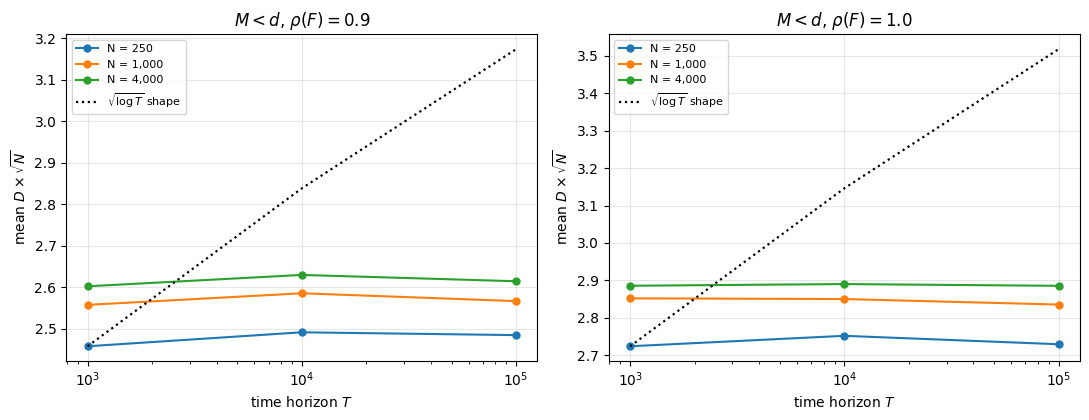

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
N_COLOR = dict(zip(N_GRID, ["tab:blue", "tab:orange", "tab:green"]))

for j, b in enumerate(B_VALS):
    for N in N_GRID:
        ys = [collapse[(b, N, T)]["ks_mean"] * math.sqrt(N) for T in T_N]
        ax[j].semilogx(T_N, ys, "o-", color=N_COLOR[N], ms=5, label=f"N = {N:,}")
    lo = np.array(T_N, float)
    anchor = collapse[(b, N_GRID[0], T_N[0])]["ks_mean"] * math.sqrt(N_GRID[0])
    ax[j].semilogx(T_N, anchor * np.sqrt(np.log(lo) / math.log(T_N[0])),
                   "k:", lw=1.6, label=r"$\sqrt{\log T}$ shape")
    ax[j].set_xlabel("time horizon $T$")
    ax[j].set_ylabel(r"mean $D \times \sqrt{N}$")
    ax[j].set_title(f"$M < d$, $\\rho(F) = {b}$")
    ax[j].legend(fontsize=8)

plt.tight_layout()
plt.show()

**Conclusion of Section 6.** On the metric the theorem is about, the collapse that Part 6 looked
for **does** happen — for the mean.

### The mean obeys $N^{-1/2}$ almost exactly

| | $T = 10^3$ | $T = 10^4$ | $T = 10^5$ |
|---|---|---|---|
| fitted exponent, $\rho = 0.9$ | $-0.479$ | $-0.481$ | $-0.482$ |
| fitted exponent, $\rho = 1.0$ | $-0.479$ | $-0.482$ | $-0.480$ |

Against a theoretical $-0.5$, and against the $-0.22$ to $-0.36$ Part 6 measured on the unbounded
metric. Rescaled, $D\sqrt{N}$ moves only from $2.46$ to $2.60$ across a $16$-fold change in $N$ at
$\rho = 0.9$, and $2.72$ to $2.89$ at $\rho = 1.0$ — around six per cent.

### But there is no $\log T$ term to find

Reading the same table along the other axis, $D\sqrt{N}$ at $N = 250$ runs $2.46$, $2.49$, $2.49$
across $T = 10^3, 10^4, 10^5$. Flat. Over those two decades $\sqrt{\log T}$ would grow by a factor
of $1.29$; the measurement gives $1.01$.

So for the mean, the requirement $N \gtrsim \log T$ of Section 7.5.2 is **conservative**: the mean
distance depends on $N$ exactly as $N^{-1/2}$ and on $T$ not at all. The horizon dependence that
the bound describes lives further out in the distribution.

### Where it does live

| statistic | fitted exponent in $N$ |
|---|---|
| mean | $-0.479$ to $-0.482$ |
| $99$th percentile | $-0.413$ to $-0.434$ |
| maximum | $-0.114$ to $-0.434$ |

The $99$th percentile departs slightly from $-1/2$; the maximum departs badly and does not collapse
at all. That is exactly what Section 5 predicts it should do — the maximum is an extreme-value
statistic, so it depends on how many draws were taken as well as how good each one is, and no
rescaling in $N$ alone can remove that.

**Part 6's negative result was real, but it was a result about the maximum of an unbounded
quantity. On the bounded metric, and for the mean, the $\sqrt{N}$ rate is recovered cleanly.**

---
## Section 7 — Summary

### What this notebook set out to do

Part 6 measured the distance between posterior means out to $T = 10^6$, found the worst case
growing like $(\log T)^{1.75}$ against the $\sqrt{\log T}$ of Del Moral & Gerber (2026),
Section 7.5.1, and closed with a caveat: the theorem bounds the **Kolmogorov distance**, which
cannot exceed $1$, while the distance between posterior means has no ceiling. This notebook
measures the bounded quantity on the same grid, so the comparison is finally like for like.

### The caveat mattered more than the measurement

Three findings, in order of how much they change the reading of Parts 1–6.

**1. The per-step error distribution is stationary, and the growth of the maximum is arithmetic.**
Across ten blocks of a million-step run, every summary of the distance agrees to within half a per
cent — mean, median, $q_{90}$, $q_{99}$, $q_{99.9}$, and the rate of exceeding $0.25$. The maximum
at any horizon is then predicted from the $(1-1/T)$ quantile of that distribution, with nothing
fitted, to within $15\%$ over four decades. **Longer runs do not degrade the filter; they give more
chances to observe the same rare bad step.**

**2. On the right metric, at the right place in the distribution, the predicted shape appears.**
The $99.9$th percentile grows by $1.46$–$2.31$ over $T: 10^2 \to 10^6$, bracketing the $1.732$ that
$\sqrt{\log T}$ predicts, with fitted exponent $0.346$–$0.714$ bracketing $0.5$. Meanwhile the mean
is flat ($1.00$–$1.07$) and the maximum grows $2.95$–$4.00$ — so *which statistic* is reported
decides whether the theory appears to hold.

**3. The $\sqrt{N}$ collapse is recovered.** The mean distance decays as $N^{-0.479}$ to
$N^{-0.482}$ against a theoretical $-1/2$, where Part 6 measured $-0.22$ to $-0.36$ on the
unbounded metric. The maximum still does not collapse, which finding 1 explains.

### Two by-products

**The metric calibrates the cloud.** An exact sample of size $N$ scores $1.017/\sqrt{N}$, so a
particle cloud scoring $D$ is worth about $(1.017/D)^2$ independent draws. At $N = 1000$ the
regimes come out at $236$, $174$, $156$ and $128$ effective draws — between $13\%$ and $24\%$ of
nominal. No quantity used in Parts 1–6 can be calibrated this way, because none of them is a
probability.

**It also sees the cloud, not just the answer.** Against $\log(\text{ESS})$ the Kolmogorov distance
correlates at $-0.654$ where the mean distance manages $-0.300$, and any step whose ESS collapses
to one particle scores at least $0.5$ by construction.

### Honest limits

- The distance is taken over the $d$ coordinate axes. Section 3 shows the supremum over $64$
  additional random directions is a near-constant $1.21\times$ larger, so growth rates are
  unaffected, but this is the **marginal** Kolmogorov distance and not the $d$-dimensional orthant
  version the theory uses.
- $T = 10^6$ was run with a single seed. The mean and quantiles rest on $10^6$ per-step
  measurements and are precise; the maximum there is one draw of an extreme, and Section 5 is what
  licenses reading it.
- Section 7.5.2 is a statement about what $N$ guarantees a fixed precision. Section 6 tests its
  consequence at fixed $N$, which is a necessary condition for the bound to be tight, not the bound
  itself.

### What follows

Section 6 shows the horizon dependence sits in the upper tail rather than the mean. Measuring
*where* it enters — which quantile first picks up a $\log T$ term — would sharpen Section 7.5.2's
reading, and costs nothing beyond rerunning Section 6 on a finer quantile grid.